# Проект - нейросеть для предсказания калорийности блюд

## Блок инициализации

In [1]:
# импорты
import pathlib as path
import random
import numpy as np
import torch
import matplotlib.pyplot as plt

# local scripts
import scripts.utils as utils

model_config = utils.MealModelConfig()

SEED = model_config.SEED

# задание случайностей - seed
utils.set_random(SEED)

# перенести в .env?
DATA_PATH = path.Path('data')

## Этап 1 - проведение исследовательского анализа данных

Рассмотрим представленный датасет:
- проведем количественный анализ данных
- проанализируем распределение численных значений калорий и массы
- проверим есть ли пропуски, выбросы, дубли


### Блюда

In [3]:
# анализ датасета по блюдам

import pandas as pd

dish_df = pd.read_csv(DATA_PATH / 'dish.csv')

display(dish_df.head())
dish_df.info()

# результат - нет пропусков (null-значений)

,dish_id,total_calories,total_mass,ingredients,split
0,dish_1561662216,300.794281,193.0,ingr_0000000508;ingr_0000000122;ingr_000000002...,test
1,dish_1561662054,419.438782,292.0,ingr_0000000312;ingr_0000000026;ingr_000000002...,train
2,dish_1562008979,382.936646,290.0,ingr_0000000448;ingr_0000000520;ingr_000000046...,test
3,dish_1560455030,20.590000,103.0,ingr_0000000471;ingr_0000000031;ingr_0000000347,train
4,dish_1558372433,74.360001,143.0,ingr_0000000453,train


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3262 entries, 0 to 3261
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   dish_id         3262 non-null   object 
 1   total_calories  3262 non-null   float64
 2   total_mass      3262 non-null   float64
 3   ingredients     3262 non-null   object 
 4   split           3262 non-null   object 
dtypes: float64(2), object(3)
memory usage: 127.5+ KB


In [ ]:
# есть ли дубли
print('Дубликаты: ', dish_df.duplicated().sum())
# результат - нет дублей

# распределение численных значений - калории и масса
print('Распределение численных значений - калории и масса')
dish_df.describe()

# результат:
# - есть выбросы - требуется детальное исследование
#     - минимальное значение калорий - 0, 1 - для массы
#     - максимальные значения 3943, 3051
# - среднее - 255, 214
# - значения не сильно смещены

Дубликаты:  0
Распределение численных значений - калории и масса


,total_calories,total_mass
count,3262.000000,3262.000000
mean,255.012738,214.980074
std,219.637570,161.497428
min,0.000000,1.000000
25%,80.114996,92.000000
50%,209.110062,177.000000
75%,375.122963,305.000000
max,3943.325195,3051.000000


In [ ]:
# какое соотношение train/test

dish_df['split'].value_counts()
#train - 2755 / test - 507 - примерно 18% на test

split
train    2755
test      507
Name: count, dtype: int64

In [ ]:
# распределение средних/отклонений - потребуется для нормализации
target_split_stats = dish_df.groupby('split')['total_calories'].agg(['mean','std'])
target_split_stats

,mean,std
split,,
test,255.467051,212.241674
train,254.929131,221.009051


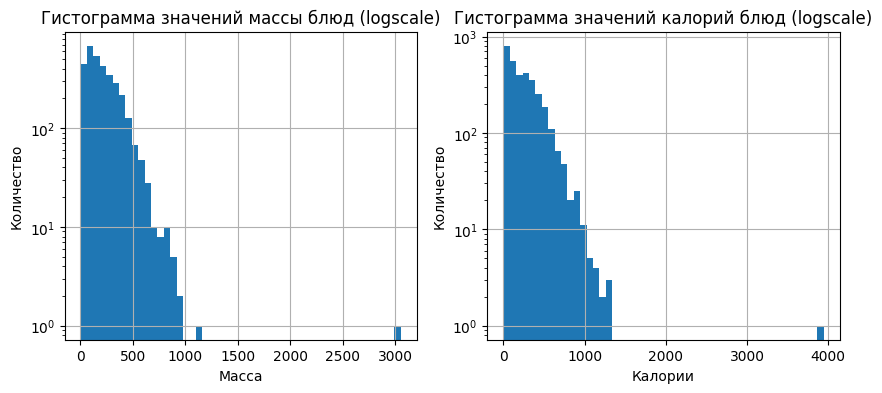

In [ ]:
# гистограммы численных значений - калории и масса

fig, axs = plt.subplots(1,2, figsize=(10,4))
ax = dish_df['total_mass'].plot.hist(bins=50, log=True, grid=True, xlabel='Масса', ylabel="Количество", title='Гистограмма значений массы блюд (logscale)', ax=axs[0])
ax = dish_df['total_calories'].plot.hist(bins=50, log=True, grid=True, xlabel='Калории', ylabel="Количество", title='Гистограмма значений калорий блюд (logscale)', ax=axs[1])

### Ингредиенты

count    3262.000000
mean        7.313305
std         6.943276
min         1.000000
25%         1.000000
50%         4.000000
75%        12.000000
max        34.000000
Name: ing_count, dtype: float64


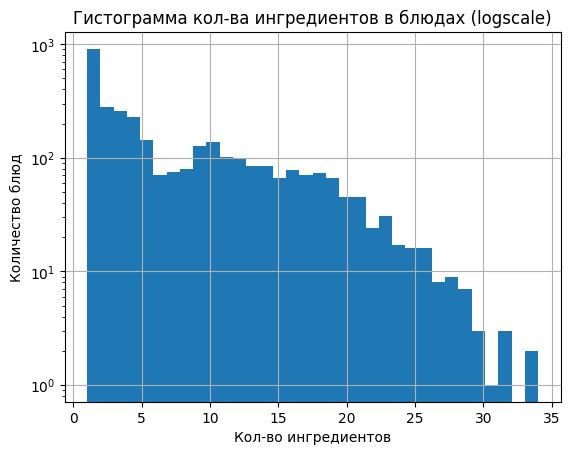

In [97]:
# распределение количества ингредиентов в блюде

dish_df['ing_count'] = dish_df['ingredients'].str.split(';').apply(len)
print(dish_df['ing_count'].describe())

ax = dish_df['ing_count'].plot.hist(bins=34, log=True, grid=True, xlabel='Кол-во ингредиентов', ylabel="Количество блюд", title='Гистограмма кол-ва ингредиентов в блюдах (logscale)')

In [ ]:
# ингредиенты
ingredients_df = pd.read_csv(DATA_PATH / 'ingredients.csv')

display(ingredients_df)
print(ingredients_df.info())
print('\n------')
print('Дубли (полные):', ingredients_df.duplicated().sum())
print('Дубли (название):', ingredients_df['ingr'].duplicated().sum())
print('Уникальные записи:\n', ingredients_df.nunique())

print('\n------')
print('Дубли (название):\n', ingredients_df[ingredients_df['ingr'].duplicated()])

# 555 значений, без пропусков
# 3 дубля по названию "deprecated"
# всего 552 уникальных названия

,id,ingr
0,1,cottage cheese
1,2,strawberries
2,3,garden salad
3,4,bacon
4,5,potatoes
...,...,...
550,551,pizza sauce
551,552,pomegranate
552,553,nut cheese
553,554,soy sausage


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 555 entries, 0 to 554
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      555 non-null    int64 
 1   ingr    555 non-null    object
dtypes: int64(1), object(1)
memory usage: 8.8+ KB
None

------
Дубли (полные): 0
Дубли (название): 3
Уникальные записи:
 id      555
ingr    552
dtype: int64

------
Дубли (название):
       id        ingr
452  453  deprecated
457  458  deprecated
469  470  deprecated


In [113]:
# объединим блюда и ингедиенты для удобства восприятия и посмотрим крайние значения
meal_df = dish_df.copy()

# разделяем строку на отдельные ингредиенты
meal_df['ingredients'] = meal_df['ingredients'].str.split(';')

# распаковываем каждый ингредиент в отдельную строку
meal_df = meal_df.explode('ingredients')

# удаляем лишние символы - 'ingr_0000000', т.к. у нас всего 555 ингредиентов, то формат этой строки константный
meal_df['ingredients'] = meal_df['ingredients'].apply(lambda ing: ing.split('ingr_0000000')[1])

# убираем ведущие нули и превращаем в int-значение идентификатора
meal_df['ingredients'] = meal_df['ingredients'].astype('int')

# делаем внешнее слияние с ингредиентами, чтобы иметь их названия в одном представлении и увидеть у кого нет соответсвия после пересечения
meal_df = meal_df.merge(ingredients_df.set_index('id'), left_on='ingredients', right_on='id', how='outer')
meal_df

,dish_id,total_calories,total_mass,ingredients,split,ing_count,ingr
0,dish_1563468327,351.886047,483.0,1.0,train,7.0,cottage cheese
1,dish_1563468299,210.350006,385.0,1.0,train,4.0,cottage cheese
2,dish_1561741063,132.300003,135.0,1.0,test,1.0,cottage cheese
3,dish_1561393619,234.040009,284.0,1.0,train,2.0,cottage cheese
4,dish_1561393550,172.480011,176.0,1.0,train,1.0,cottage cheese
...,...,...,...,...,...,...,...
24206,NaN,NaN,NaN,NaN,NaN,NaN,pizza sauce
24207,NaN,NaN,NaN,NaN,NaN,NaN,pomegranate
24208,NaN,NaN,NaN,NaN,NaN,NaN,nut cheese
24209,NaN,NaN,NaN,NaN,NaN,NaN,soy sausage


In [114]:
# есть ли блюда, которые ссылаются на неизвестные инегредиенты 
print('Блюда с неизвестными ингредиентами:', meal_df["ingr"].isna().sum())

# нет таких

Блюда с неизвестными ингредиентами: 0


In [ ]:
# есть ли ингредиенты, которые не попали ни в одно блюда
print('Ингредиенты, не попавшие ни в одно блюдо:', meal_df["dish_id"].isna().sum())

# 355 таких 

meal_df[meal_df["dish_id"].isna()]

Ингредиенты, не попавшие ни в одно блюдо: 355


,dish_id,total_calories,total_mass,ingredients,split,ing_count,ingr
1874,NaN,NaN,NaN,NaN,NaN,NaN,turkey
1876,NaN,NaN,NaN,NaN,NaN,NaN,duck
2075,NaN,NaN,NaN,NaN,NaN,NaN,guacamole
2296,NaN,NaN,NaN,NaN,NaN,NaN,artic char
5815,NaN,NaN,NaN,NaN,NaN,NaN,bean sprouts
...,...,...,...,...,...,...,...
24206,NaN,NaN,NaN,NaN,NaN,NaN,pizza sauce
24207,NaN,NaN,NaN,NaN,NaN,NaN,pomegranate
24208,NaN,NaN,NaN,NaN,NaN,NaN,nut cheese
24209,NaN,NaN,NaN,NaN,NaN,NaN,soy sausage


In [ ]:
# оставим только блюда с ингредиентами
meal_df = meal_df[meal_df["dish_id"].notna()]

print('в блюдах содержится уникальных ингредиентов', meal_df['ingr'].nunique())
# 199 уникальных ингредиентов по названию

# выделим в отдельный датасет блюда с удаленными ингредиентами
bad_meal_df = meal_df[meal_df['ingr'] == 'deprecated']

print('блюда с "удаленными" ингредиентами', bad_meal_df.shape[0])
display(bad_meal_df.head())
display(bad_meal_df.tail())

# 31 блюдо содержит "удаленный" ингредиент
# выборочная проверка - "deprecated" ингредиента это яблоки, и что-то похожее на кубики нарезанного арбуза

# какое соотношение train/test
bad_meal_df['split'].value_counts()

# 23 / 8

в блюдах содержится уникальных ингредиентов 199
блюда с "удаленными" ингредиентами 31


,dish_id,total_calories,total_mass,ingredients,split,ing_count,ingr
18673,dish_1558372433,74.360001,143.0,453.0,train,1.0,deprecated
18674,dish_1558114086,74.360001,143.0,453.0,test,1.0,deprecated
18675,dish_1558373159,1013.337036,334.0,453.0,test,3.0,deprecated
18676,dish_1558115364,485.260010,313.0,453.0,train,4.0,deprecated
18677,dish_1558114875,74.360001,143.0,453.0,train,1.0,deprecated


,dish_id,total_calories,total_mass,ingredients,split,ing_count,ingr
18725,dish_1558028606,19.500000,65.0,458.0,train,1.0,deprecated
18726,dish_1558031394,237.410004,318.0,458.0,test,4.0,deprecated
18727,dish_1558028772,64.000000,192.0,458.0,train,3.0,deprecated
18728,dish_1558031351,12.300000,41.0,458.0,test,1.0,deprecated
18729,dish_1558028194,228.050003,172.0,458.0,train,3.0,deprecated


split
train    23
test      8
Name: count, dtype: int64

In [154]:
# Сохраним список блюд с "удаленными" ингредиентами в файл

bad_meal_df.to_csv(DATA_PATH / 'bad_meal.csv', index=False)

### Очистка блюд с "удаленными" игредиентами

Так как модель будет пытаться сформировать неверные связи на "удаленных" ингредиентах, целесообразно их удалить / отфильтровать
- 31 блюдо из 3262 - это 0.95% - не существенно

В целом надо бы их в будущем как-то исправить, чтобы не удалять и не терять часть выборки.

In [157]:
meal_cleaned_df = meal_df[~meal_df['dish_id'].isin(bad_meal_df['dish_id'])]

# сохраним в файл
meal_cleaned_df.to_csv(DATA_PATH / 'meal_cleaned.csv', index=False)

# Теперь остались только известные ингредиенты
print('Количество блюд после очистки:', meal_cleaned_df['dish_id'].nunique())

meal_cleaned_df

Количество блюд после очистки: 3231


,dish_id,total_calories,total_mass,ingredients,split,ing_count,ingr
0,dish_1563468327,351.886047,483.0,1.0,train,7.0,cottage cheese
1,dish_1563468299,210.350006,385.0,1.0,train,4.0,cottage cheese
2,dish_1561741063,132.300003,135.0,1.0,test,1.0,cottage cheese
3,dish_1561393619,234.040009,284.0,1.0,train,2.0,cottage cheese
4,dish_1561393550,172.480011,176.0,1.0,train,1.0,cottage cheese
...,...,...,...,...,...,...,...
24197,dish_1565020895,348.126129,416.0,545.0,test,8.0,greek yogurt
24198,dish_1564588889,234.494431,346.0,545.0,test,5.0,greek yogurt
24199,dish_1562691705,412.676880,554.0,545.0,train,10.0,greek yogurt
24200,dish_1562691737,485.676880,700.0,545.0,train,11.0,greek yogurt


In [ ]:
# посмотрим распределение ингредиентов по популярности

ingr_popularity = meal_cleaned_df.groupby(by='ingr')['dish_id'].count().sort_values(ascending=False)
ingr_popularity

# приправа на 1-х местах

ingr
olive oil            1561
salt                 1379
garlic                947
pepper                723
vinegar               713
                     ... 
mozzarella cheese       1
orange with peel        1
toast                   1
syrup                   1
wheat bread             1
Name: dish_id, Length: 198, dtype: int64

### Сводный датасет по блюдам и названиям ингредиентов

Соединим обратно все ингредиенты в строку для удобства

In [204]:
meal_combined_df = (
    meal_cleaned_df.groupby(['dish_id', 'total_calories', 'total_mass', 'split', 'ing_count'], dropna=False)
      .agg(
          ingr_id=('ingredients', list),
          ingr_name=('ingr', list),
      )
      .reset_index()
      .sort_values(by='dish_id')
)

# сохраним в файл
meal_combined_df.to_csv(DATA_PATH / 'meal_combined.csv', index=False)

meal_combined_df

,dish_id,total_calories,total_mass,split,ing_count,ingr_id,ingr_name
0,dish_1556572657,41.399998,36.0,train,1.0,[12.0],[olives]
1,dish_1556573514,6.440000,23.0,train,1.0,[29.0],[mixed greens]
2,dish_1556575014,71.299995,62.0,train,1.0,[12.0],[olives]
3,dish_1556575083,27.520000,64.0,train,1.0,[16.0],[brussels sprouts]
4,dish_1556575124,4.480000,28.0,train,1.0,[34.0],[celery]
...,...,...,...,...,...,...,...
3226,dish_1568666230,55.800003,268.0,train,2.0,"[27.0, 30.0]","[broccoli, lettuce]"
3227,dish_1568666263,93.400002,348.0,train,3.0,"[27.0, 30.0, 95.0]","[broccoli, lettuce, artichokes]"
3228,dish_1568666303,443.199982,560.0,train,4.0,"[27.0, 28.0, 30.0, 95.0]","[broccoli, chicken, lettuce, artichokes]"
3229,dish_1568666329,743.760010,594.0,train,5.0,"[27.0, 28.0, 30.0, 95.0, 161.0]","[broccoli, chicken, lettuce, artichokes, olive..."


### Проверка выборосов по массе и калориям

In [ ]:
# посмотрим наименьшие значения по массе 
meal_combined_df[meal_combined_df['total_mass'] < 10].head()

# блюдо - 16 - dish_1557861216	- 0.000000 - 1.0 - ingr_0000000423 - test -> ing: 423 - plate only - это просто пустая тарелка
# блюдо - 204 - dish_1558461431	- 1.150000 - 5.0 - ingr_0000000036 - test -> ing: 36 - spinach (raw) - несколько листочков шпината

# все блюда настоящие, ошибок нет

,dish_id,total_calories,total_mass,split,ing_count,ingr_id,ingr_name
16,dish_1557861216,0.000000,1.0,test,1.0,[423.0],[plate only]
80,dish_1558110335,37.869999,7.0,test,1.0,[4.0],[bacon]
196,dish_1558459602,2.070000,9.0,train,1.0,[36.0],[spinach (raw)]
202,dish_1558460205,1.840000,8.0,train,1.0,[36.0],[spinach (raw)]
204,dish_1558461431,1.150000,5.0,test,1.0,[36.0],[spinach (raw)]


In [ ]:
# посмотрим наибольшие значения по массе 
meal_combined_df[meal_combined_df['total_mass'] > 900]

# максимальный вес - 3051.0	- по картинке явно не весит 3кг, похоже на ошибку
#   1028	dish_1560974769	3943.325195	3051.0	train	14.0	[26.0, 32.0, 36.0, 47.0, 52.0, 94.0, 122.0, 20...	[white rice, tomatoes, spinach (raw), corn, ch.

# 1333	dish_1561739805	696.363525	1102.0 - здесь похоже на 1.1 кг

,dish_id,total_calories,total_mass,split,ing_count,ingr_id,ingr_name
1028,dish_1560974769,3943.325195,3051.0,train,14.0,"[26.0, 32.0, 36.0, 47.0, 52.0, 94.0, 122.0, 20...","[white rice, tomatoes, spinach (raw), corn, ch..."
1332,dish_1561739760,452.163513,937.0,train,9.0,"[13.0, 27.0, 29.0, 37.0, 40.0, 41.0, 294.0, 33...","[berries, broccoli, mixed greens, cantaloupe, ..."
1333,dish_1561739805,696.363525,1102.0,train,10.0,"[8.0, 13.0, 27.0, 29.0, 37.0, 40.0, 41.0, 294....","[scrambled eggs, berries, broccoli, mixed gree..."
1973,dish_1563305083,1234.856323,901.0,train,29.0,"[25.0, 26.0, 27.0, 28.0, 29.0, 30.0, 35.0, 36....","[beef, white rice, broccoli, chicken, mixed gr..."
2399,dish_1564590352,497.915833,962.0,train,8.0,"[13.0, 37.0, 38.0, 121.0, 128.0, 161.0, 437.0,...","[berries, cantaloupe, pineapple, watermelon, e..."


In [ ]:
# посмотрим наименьшие значения по калориям
meal_combined_df[meal_combined_df['total_calories'] < 5].head()

# все блюда настоящие, ошибок нет, есть только логическая ошибка, что пустая тарелка весит 86.0 - должно быть около 0-1.

,dish_id,total_calories,total_mass,split,ing_count,ingr_id,ingr_name
4,dish_1556575124,4.48,28.0,train,1.0,[34.0],[celery]
11,dish_1556575700,0.00,86.0,train,1.0,[423.0],[plate only]
16,dish_1557861216,0.00,1.0,test,1.0,[423.0],[plate only]
26,dish_1557863012,3.10,31.0,train,1.0,[31.0],[cucumbers]
144,dish_1558376801,4.20,15.0,test,1.0,[29.0],[mixed greens]


In [ ]:
# посмотрим наибольшие значения по калориям 
meal_combined_df[meal_combined_df['total_calories'] > 1200]

# в целом все похоже на правду, кроме - 1028	dish_1560974769	3943.325195	3051.0 - у которого и с массой похоже на ошибку


,dish_id,total_calories,total_mass,split,ing_count,ingr_id,ingr_name
1028,dish_1560974769,3943.325195,3051.0,train,14.0,"[26.0, 32.0, 36.0, 47.0, 52.0, 94.0, 122.0, 20...","[white rice, tomatoes, spinach (raw), corn, ch..."
1534,dish_1562603895,1268.157349,517.0,train,8.0,"[8.0, 15.0, 29.0, 39.0, 40.0, 41.0, 294.0, 338.0]","[scrambled eggs, hash browns, mixed greens, sa..."
1973,dish_1563305083,1234.856323,901.0,train,29.0,"[25.0, 26.0, 27.0, 28.0, 29.0, 30.0, 35.0, 36....","[beef, white rice, broccoli, chicken, mixed gr..."
2065,dish_1563476577,1238.033691,857.0,train,30.0,"[11.0, 21.0, 23.0, 25.0, 27.0, 36.0, 46.0, 54....","[cheese pizza, squash, brown rice, beef, brocc..."
2321,dish_1564170010,1264.548340,831.0,train,23.0,"[21.0, 23.0, 27.0, 31.0, 32.0, 52.0, 60.0, 72....","[squash, brown rice, broccoli, cucumbers, toma..."
2502,dish_1565033265,1324.084961,625.0,train,6.0,"[12.0, 27.0, 28.0, 29.0, 161.0, 338.0]","[olives, broccoli, chicken, mixed greens, oliv..."


### Проверка наличия изображения для блюда

In [ ]:
# в представленном датасете есть id блюд, которых нет в dish.csv - то есть явное несоответсвие
# проверим у всех ли блюд хватает картинок

def check_img_exists(dish_id):
    return path.Path(DATA_PATH / 'images' / dish_id / 'rgb.png').exists()

meal_combined_df['img_exists'] = meal_combined_df['dish_id'].apply(lambda dish_id: check_img_exists(dish_id))

print('У скольких блюд нет картинки:', (~meal_combined_df['img_exists']).sum())

# нет блюд без картинки

У скольких блюд нет картинки: 0


In [263]:
# проверим сколько лишних картинок в датасете - у которых нет описания блюда

image_dishes = [dish.stem for dish in path.Path(DATA_PATH / 'images').iterdir()]
print('total img count:', len(image_dishes))
# 3490

image_without_dish = [img for img in image_dishes if len(meal_combined_df[meal_combined_df['dish_id'] == img]) == 0]
print('img without dish count:', len(image_without_dish))
# 259 - лишние картинки

total img count: 3490
img without dish count: 259


### Визуализируем некоторые блюда и их изображения

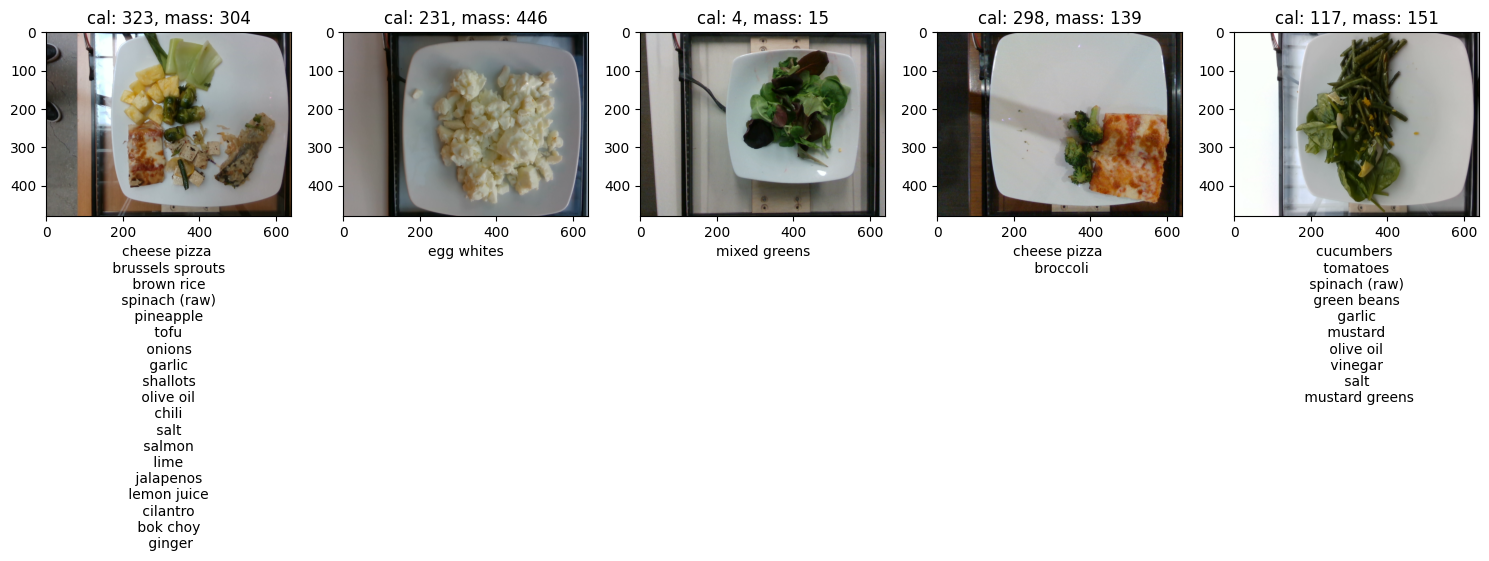

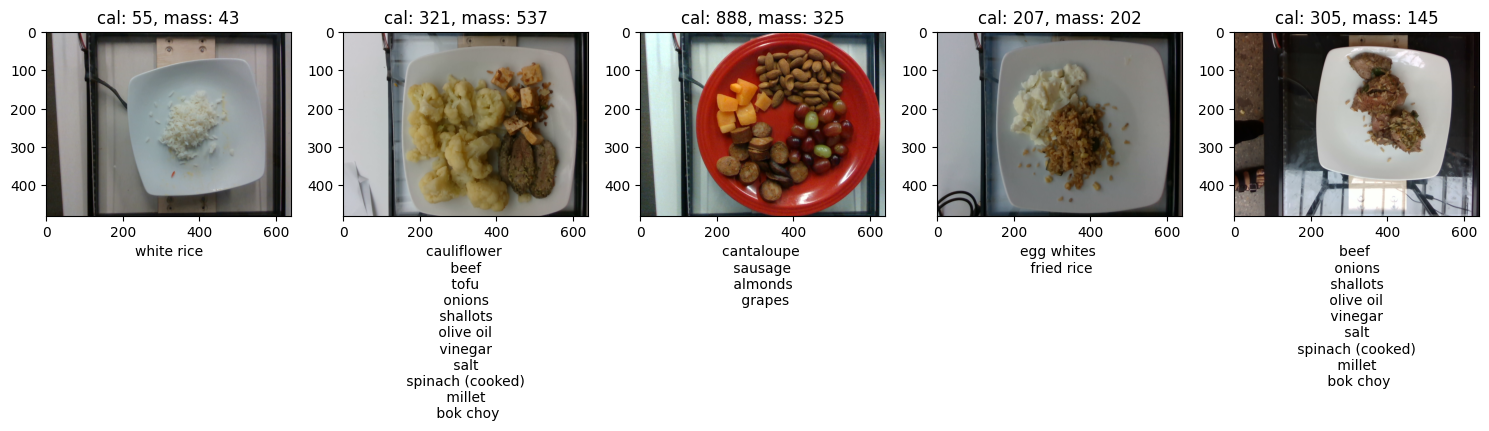

In [ ]:
from PIL import Image
n = 5

def plot_dishes(sample_dishes):
    """ 
    Выводит информацию о блюдах (до 5 штук) и их фото
    """
    n = min(len(sample_dishes), 5)
    fig, axs = plt.subplots(1,n, figsize=(3*n,5))
    for i, sample in enumerate(sample_dishes.iterrows()):
        dish = sample[1]
        img = Image.open(DATA_PATH / 'images' / dish['dish_id'] / 'rgb.png')
        
        axs[i].imshow(img)
        axs[i].set_title(f"cal: {int(dish['total_calories'])}, mass: {int(dish['total_mass'])}")
        axs[i].set_xlabel(" \n ".join(dish['ingr_name']))

    plt.tight_layout()

sample = meal_combined_df.sample(n=2*n, random_state=SEED)
plot_dishes(sample[:n])
plot_dishes(sample[n:])



### Результаты EDA
- блюда
    - всего 3262 записи
    - пропусков (null значений) нет
    - дублей нет
    - соотношение train/test
        - train - 2755 / test - 507 (18% на test)
        - среднее, и стандартное отклонение 
            - train: mean = 254.93, std = 221.01 - используем для масштабирования
            - test: mean = 255.47, std = 212.24

    - есть выбросы 
        - минимальное значение - калории - 0, масса - 1 - это пустая тарелка, не ошибка
        - среднее - калории - 255, масса - 214
        - максимальные значения - калорий 3943, масса - 3051
            - всего по 1-ому блюду - похоже на ошибку, т.к. на картинке не так много еды            
- ингредиенты
    - всего 555 ингредиентов, без пропусков 
        - 552 уникальных названия
        - 3 дубля по названию "deprecated" - "удаленные" ингредиенты
    - в блюдах содержится от 1 до 34 ингредиентов, среднее - 7
    - 355 ингредиентов / из 555 - не участвуют ни в каких блюдах,
        - значит блюда содержат всего 200 ингредиентов
    - 31 блюдо содержит "удаленный" ингредиент
        - "deprecated" ингредиенты - это яблоки, и что-то похожее на кубики нарезанного арбуза
        - это 0.95% от всей выборки (3262 записи) - не существенно
- очищенный датасет с блюдами 
    - 3231 - блюда после исключения "удаленных" ингредиентов

- объединенный очищенный датасет - блюда + ингредиенты - сохранен в `data/meal_combined.csv`.

- изображения
    - всего предоставлено изображений - 3490, размер - (640, 480) px RGB-формат
    - 259 лишних картинок, для которых нет описания блюда
    - у всех блюд при этом есть картинка - то есть проблем в сопоставлении не будет

### Подход к решению задачи

#### Определение признаков

У нас есть следующий набор признаков для каждого блюда:
- список названий ингредиентов, входящих в блюдо
    - вар.1 - ингредиенты можно представить в виде one-hot кодирования - тогда для каждого блюда будет свой цифровой отпечаток - но это бы подошло для классической модели
    - вар.2 - можно представить список всех ингредиентов как текстовое "предложение"
        - порядок следования "слов/ингредиентов" может содержать информацию об относительной массе или калорийности этого слова в общем составе
        - поэтому подойдет простая модель RNN-модель, например GRU, так как длина предложения ограничена всего 34 "словами"
        - такая модель на выходе выдаст эмбеддинг - закодированный набор признаков всего блюда
            
- общая масса блюда 
    - может быть полезной характеристикой, сильно корреклирует с калорийностью
    - вопрос куда его передавать? в нейросеть нельзя передать 
        - если только на выходе из НС добавлять еще модель для регрессии и в нее включать все признаки, в том числе эмбеддинги
        - пока отложим этот вопрос до построения базовой модели NLP + CV

- изображение
    - вопрос - зачем модели дополнительная информация об изображении, если она получает на вход тестовый состав ингредиентов?
        - значит, изображение поможет определить виден ли вообще продукт на изображении, например "соль" не видна, и ее наличие в составе не влияет на калорийность 
            - это важная информация для модели
        - также из картинке можно извлечь размер (объем) продукта - много/мало - это влияет на калорийность 
    - таким образом, по картинке модель должна извлечь эмбеддинг - какие же "объекты/продукты" реально присутсвуют на фото
    - изображения 3-х канальные (640, 480) px с множеством элементов - то есть модель должна быть достаточно сложной, чтобы отделять продукты друг от друга
    - так как возможно использование модели на мобильных устройствам начнем с облегченной модели MobileNet
- таким образом получим закодированные признаки:
    - эмбеддинг от текстовой (NLP) модели
    - эмбеддинг от визуальной (CV) MobileNet-модели
    - объединять их будем через механизм CrossAttention, который как раз выполняет поиск "токенов" на "изображении".
    - [UPDATE] - CrossAttention не сработал, так как используется всего один "токен" от текста ([CLS]) - и так как Softmax от 1-ого элемента дает 1, выход совпадает с признаками изображения, что полностью "гасит" признаки текста
        - поэтому заменяем CrossAttention простой конкатенацией с линейным слоем + акивацией, чтобы использовались признаки обоих модальностей

---

- выбор модели для текста 
    - варианты: 
        1) простая GRU на PyTorch 
        2) BERT-модель 
        3) GPT-модель - какой выбрать:
    - модель BERT (`distilbert-base-uncased`) - это двунаправленный трансформер:
        - он содержит специальный 1-ый токен во входной последовательности `[CLS]`, который содержит информацию обо всем тексте
        - поэтому, чтобы извлечь признаки "предложения" с ингердиентами достаточно извлечь скрытый слой (эмбеддинг) этого токена
        - количество параметров - 66,362,880
        - размер словаря - 30,522
        - размерность признаков: 768
    - у GPT-2 нет такого спец токена-агрегатора (модель однонаправленная), и модель более тяжелая
        - количество параметров - 81,912,576
        - размер словаря - 50257
        - размерность признаков: 768
    - таким образом BERT-модель более легкая и более удобная для данной задачи 
        - возьмем для начала `distilbert-base-uncased`
    - также в запасе будем держать разработку модели с нуля на базе GRU с обучаемым слоем эмбеддинга 
        - так как "словарь" ингредиентов у нас всего 34 слова - обучить такую модель должно быть довольно просто
    
- для изображений - облегченная модель MobileNet 
    - возьмем для начала самую актуальную и мощную MobileNetV4 модель на сегодня - `mobilenetv4_conv_aa_large.e230_r448_in12k_ft_in1k`
    - размерность признаков - 960
    - количество параметров - 31,309,864

#### Какая нужна предобработка

- Аугментация изображений
    - Изображения имееют прямоугольный формат (640, 480)
    - модель `mobilenetv4_conv_aa_large.e230_r448_in12k_ft_in1k` обучена на размере изображения 448x448 px, что близко к нашим изображениям:
        - потребуется выполнить преобразования `SmallestMaxSize` + `RandomCrop` для "вырезания" квадратных картинок нужного размера
        - продукты на фото все в разных местах, и качество довольно низкое, поэтому дополнительные пространственные и цветовые аугментации кажутся избыточными
- при fine-tune обучении моделей и переообучении - рассмотреть дополнительные аугментации

#### Какие метрики использовать
- так как у нас задача регрессии - предсказать конкретное число калорий - применимы метрики MSE, MAE
- для стабилизации обучения, будем использовать функцию Huber (сочетания MSE и MAE) - см. аргументы выше
- а метрику качества - MAE, так как по ней требуется выполнить оценку модели

## Этап 2 - реализация пайплайна обучения

**Результаты**:
- python-файлы с воспроизводимым кодом обучения
- все результаты должны воспроизводиться путем вызова `train` с передаче конфигурационного файла

### Текстовые модели - обзор параметров - BERT vs GPT2

#### distilbert-base-uncased

In [33]:
from transformers import AutoTokenizer, AutoModel, DistilBertModel
import numpy as np

bert_model_name = "distilbert-base-uncased"
bert_model = AutoModel.from_pretrained(bert_model_name)
bert_tokenizer = AutoTokenizer.from_pretrained(bert_model_name)

bert_model_size = np.sum([p.numel() for p in bert_model.parameters()])

print(f'model = {bert_model_name}')
print(f'model param size = {bert_model_size:,d}')
print(f'feature size: {bert_model.config.hidden_size}')
print('---------')

print('model architecture')
display(bert_model)

print('---------')
print('model config')
display(bert_model.config)

print('---------')
print('tokenizer')
display(bert_tokenizer)

model = distilbert-base-uncased
model param size = 66,362,880
feature size: 768
---------
model architecture


DistilBertModel(
  (embeddings): Embeddings(
    (word_embeddings): Embedding(30522, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (transformer): Transformer(
    (layer): ModuleList(
      (0-5): 6 x TransformerBlock(
        (attention): DistilBertSdpaAttention(
          (dropout): Dropout(p=0.1, inplace=False)
          (q_lin): Linear(in_features=768, out_features=768, bias=True)
          (k_lin): Linear(in_features=768, out_features=768, bias=True)
          (v_lin): Linear(in_features=768, out_features=768, bias=True)
          (out_lin): Linear(in_features=768, out_features=768, bias=True)
        )
        (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
        (ffn): FFN(
          (dropout): Dropout(p=0.1, inplace=False)
          (lin1): Linear(in_features=768, out_features=3072, bias=True)
          (lin2): L

---------
model config


DistilBertConfig {
  "activation": "gelu",
  "architectures": [
    "DistilBertForMaskedLM"
  ],
  "attention_dropout": 0.1,
  "dim": 768,
  "dropout": 0.1,
  "hidden_dim": 3072,
  "initializer_range": 0.02,
  "max_position_embeddings": 512,
  "model_type": "distilbert",
  "n_heads": 12,
  "n_layers": 6,
  "pad_token_id": 0,
  "qa_dropout": 0.1,
  "seq_classif_dropout": 0.2,
  "sinusoidal_pos_embds": false,
  "tie_weights_": true,
  "torch_dtype": "float32",
  "transformers_version": "4.52.4",
  "vocab_size": 30522
}

---------
tokenizer


DistilBertTokenizerFast(name_or_path='distilbert-base-uncased', vocab_size=30522, model_max_length=512, is_fast=True, padding_side='right', truncation_side='right', special_tokens={'unk_token': '[UNK]', 'sep_token': '[SEP]', 'pad_token': '[PAD]', 'cls_token': '[CLS]', 'mask_token': '[MASK]'}, clean_up_tokenization_spaces=False, added_tokens_decoder={
	0: AddedToken("[PAD]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	100: AddedToken("[UNK]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	101: AddedToken("[CLS]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	102: AddedToken("[SEP]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	103: AddedToken("[MASK]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
}
)

#### distilgpt2

In [32]:
import numpy as np

gpt_model_name = "distilgpt2"
gpt_model = AutoModel.from_pretrained(gpt_model_name)
gpt_tokenizer = AutoTokenizer.from_pretrained(gpt_model_name)

gpt_model_size = np.sum([p.numel() for p in gpt_model.parameters()])

print(f'model = {gpt_model_name}')
print(f'model param size = {gpt_model_size:,d}')
print(f'feature size: {gpt_model.config.hidden_size}')
print('---------')

print('model architecture')
display(gpt_model)

print('---------')
print('model config')
display(gpt_model.config)

print('---------')
print('tokenizer')
display(gpt_tokenizer)


model = distilgpt2
model param size = 81,912,576
feature size: 768
---------
model architecture


GPT2Model(
  (wte): Embedding(50257, 768)
  (wpe): Embedding(1024, 768)
  (drop): Dropout(p=0.1, inplace=False)
  (h): ModuleList(
    (0-5): 6 x GPT2Block(
      (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
      (attn): GPT2Attention(
        (c_attn): Conv1D(nf=2304, nx=768)
        (c_proj): Conv1D(nf=768, nx=768)
        (attn_dropout): Dropout(p=0.1, inplace=False)
        (resid_dropout): Dropout(p=0.1, inplace=False)
      )
      (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
      (mlp): GPT2MLP(
        (c_fc): Conv1D(nf=3072, nx=768)
        (c_proj): Conv1D(nf=768, nx=3072)
        (act): NewGELUActivation()
        (dropout): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (ln_f): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
)

---------
model config


GPT2Config {
  "_num_labels": 1,
  "activation_function": "gelu_new",
  "architectures": [
    "GPT2LMHeadModel"
  ],
  "attn_pdrop": 0.1,
  "bos_token_id": 50256,
  "embd_pdrop": 0.1,
  "eos_token_id": 50256,
  "id2label": {
    "0": "LABEL_0"
  },
  "initializer_range": 0.02,
  "label2id": {
    "LABEL_0": 0
  },
  "layer_norm_epsilon": 1e-05,
  "model_type": "gpt2",
  "n_ctx": 1024,
  "n_embd": 768,
  "n_head": 12,
  "n_inner": null,
  "n_layer": 6,
  "n_positions": 1024,
  "reorder_and_upcast_attn": false,
  "resid_pdrop": 0.1,
  "scale_attn_by_inverse_layer_idx": false,
  "scale_attn_weights": true,
  "summary_activation": null,
  "summary_first_dropout": 0.1,
  "summary_proj_to_labels": true,
  "summary_type": "cls_index",
  "summary_use_proj": true,
  "task_specific_params": {
    "text-generation": {
      "do_sample": true,
      "max_length": 50
    }
  },
  "torch_dtype": "float32",
  "transformers_version": "4.52.4",
  "use_cache": true,
  "vocab_size": 50257
}

---------
tokenizer


GPT2TokenizerFast(name_or_path='distilgpt2', vocab_size=50257, model_max_length=1024, is_fast=True, padding_side='right', truncation_side='right', special_tokens={'bos_token': '<|endoftext|>', 'eos_token': '<|endoftext|>', 'unk_token': '<|endoftext|>'}, clean_up_tokenization_spaces=False, added_tokens_decoder={
	50256: AddedToken("<|endoftext|>", rstrip=False, lstrip=False, single_word=False, normalized=True, special=True),
}
)

### CV-модели - обзор параметров

#### mobilenetv4_conv_aa_large

In [ ]:
import timm
import pprint

mobilenet_model = 'mobilenetv4_conv_aa_large'
img_model = timm.create_model(model_name=mobilenet_model, pretrained=True, num_classes=0)
img_model_congif = timm.get_pretrained_cfg(model_name=mobilenet_model)
img_model_size = np.sum([p.numel() for p in img_model.parameters()])

print(f'feature size: {img_model.num_features}')
print(f'model param size = {img_model_size:,d}')

print(f'----------')
print(f'model architecture')
display(img_model)

print(f'----------')
print(f'model config')
pprint.pprint(img_model_congif)


feature size: 960
model param size = 31,309,864
----------
model architecture


MobileNetV3(
  (conv_stem): Conv2d(3, 24, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
  (bn1): BatchNormAct2d(
    24, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True
    (drop): Identity()
    (act): ReLU(inplace=True)
  )
  (blocks): Sequential(
    (0): Sequential(
      (0): EdgeResidual(
        (conv_exp): Conv2d(24, 96, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNormAct2d(
          96, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True
          (drop): Identity()
          (act): ReLU(inplace=True)
        )
        (aa): AvgPool2d(kernel_size=2, stride=2, padding=0)
        (se): Identity()
        (conv_pwl): Conv2d(96, 48, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn2): BatchNormAct2d(
          48, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True
          (drop): Identity()
          (act): Identity()
        )
        (drop_path): Identity()
      )
    )
   

----------
model config
PretrainedCfg(url='',
              file=None,
              state_dict=None,
              hf_hub_id='timm/mobilenetv4_conv_aa_large.e230_r448_in12k_ft_in1k',
              hf_hub_filename=None,
              source=None,
              architecture='mobilenetv4_conv_aa_large',
              tag='e230_r448_in12k_ft_in1k',
              custom_load=False,
              input_size=(3, 448, 448),
              test_input_size=(3, 544, 544),
              min_input_size=None,
              fixed_input_size=False,
              interpolation='bicubic',
              crop_pct=0.95,
              test_crop_pct=1.0,
              crop_mode='center',
              mean=(0.485, 0.456, 0.406),
              std=(0.229, 0.224, 0.225),
              num_classes=1000,
              label_offset=None,
              label_names=None,
              label_descriptions=None,
              pool_size=(14, 14),
              test_pool_size=None,
              first_conv='conv_stem',


### Пайплайн обучения

In [59]:
import importlib 
import scripts.dataset as dataset
import scripts.utils as utils

importlib.reload(dataset)
importlib.reload(utils)

<module 'scripts.utils' from 'd:\\Обучение\\DeepLearning\\Яндекс-DL\\Projects\\4-sprint-food-calories\\scripts\\utils.py'>

#### Эксперимент 1 - замороженные модели + fusion-слой

In [20]:
import numpy as np
import pandas as pd
import pathlib as path
from functools import partial
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel

# local scripts
import scripts.dataset as dataset
import scripts.utils as utils

config = utils.MealModelConfig()

utils.set_random(config.SEED)
log = partial(utils.log_fn, config=config)

tokenizer = AutoTokenizer.from_pretrained(config.TEXT_MODEL_NAME)

train_dataset = dataset.MealDataset(model_config=config, split='train')
train_dataloader = DataLoader(dataset=train_dataset, batch_size=config.N_BATCH, shuffle=True, collate_fn=partial(dataset.collate_fn, tokenizer=tokenizer))

val_dataset = dataset.MealDataset(model_config=config, split='test')
val_dataloader = DataLoader(dataset=val_dataset, batch_size=config.N_BATCH, shuffle=False, collate_fn=partial(dataset.collate_fn, tokenizer=tokenizer))

model = utils.MealModelNN(config=config) 

# разморозка параметров
utils.unfreeze_model_params(model, config)

# подключаем обучаемые (активные) параметры к оптимизатору
optimizer = torch.optim.AdamW([
    # [TODO] проверить/почистить пустые группы, если нет обучаемых параметров
    {'params': [p for p in model.text_model.parameters() if p.requires_grad], 'lr': config.LR_TEXT_MODEL},
    {'params':[p for p in model.img_model.parameters() if p.requires_grad], 'lr': config.LR_IMG_MODEL},
    
    {'params': model.text_proj.parameters(), 'lr': config.LR_PROJ},
    {'params': model.img_proj.parameters(), 'lr': config.LR_PROJ},
    {'params': model.norm_layer.parameters(), 'lr': config.LR_PROJ},
    {'params': model.fusion.parameters(), 'lr': config.LR_FUSION},
    {'params': model.regression_head.parameters(), 'lr': config.LR_REGRESSION_HEAD}
])

# проверка, что все активные параметры добавлены в оптимизатор
utils.optimizer_params_sanity_check(model, optimizer)

# - прогрев learning rate warmup
scheduler = torch.optim.lr_scheduler.LambdaLR(
    optimizer,
    lr_lambda=lambda step: min(1.0, step / 200)  # 200 шагов ≈ 1+ эпоха
)

print(f'batch size = {config.N_BATCH}')
print(f'n_iter = {config.N_ITER}')
print(f'train iterations/batch = {len(train_dataloader)}')
print(f'val iterations/batch = {len(val_dataloader)}')

train_loss_history = []
train_mae_history = []
train_time_history = []
val_loss_history = []
val_mae_history = []
val_time_history = []
best_metric = 1000
best_epoch = -1
for epoch in range(config.N_EPOCHS):
    train_huber_loss, train_metric_mae, train_time = utils.train(model=model, config=config, optimizer=optimizer, dataloader=train_dataloader, scheduler=scheduler)
    train_loss_history.append(train_huber_loss)
    train_mae_history.append(train_metric_mae)
    train_time_history.append(train_time)

    val_loss_huber, val_metric_mae, val_time = utils.validate(model=model, config=config, dataloader=val_dataloader)
    val_loss_history.append(val_loss_huber)
    val_mae_history.append(val_metric_mae)
    val_time_history.append(val_time)

    print(f'epoch - {epoch}: train mae = {train_metric_mae:.2f}, train_loss = {train_huber_loss:.2f}/{train_time:.2f} sec, val_mae = {val_metric_mae:.2f}, val_loss = {val_loss_huber:.2f}/{val_time:.2f} sec')
       
    if val_metric_mae < best_metric:
        best_metric = val_metric_mae
        best_epoch = epoch
        utils.save_model(model, config)

    # если метрика не уменьшается в течение config.PATIENCE эпох подряд, то останавливаем обучение
    if (epoch - best_epoch) >= config.PATIENCE:
        print(f'early stopping - metric is not increasing for [{config.PATIENCE}] epochs')
        break


    if val_metric_mae < config.TARGET_METRIC:
        print(f'!! target metric reached = {config.TARGET_METRIC}, stop training')
        break

# save train logs
log_path  = path.Path(config.MODEL_LOG_SAVE_PATH)
log_path.mkdir(exist_ok=True)

pd.DataFrame(train_loss_history, columns=['loss_huber']).to_csv(log_path / 'train_loss_history.csv', index=False)
pd.DataFrame(train_mae_history, columns=['metric_mae']).to_csv(log_path / 'train_mae_history.csv', index=False)
pd.DataFrame(train_time_history, columns=['time']).to_csv(log_path / 'train_time_history.csv', index=False)

pd.DataFrame(val_loss_history, columns=['loss_huber']).to_csv(log_path / 'val_loss_history.csv', index=False)
pd.DataFrame(val_mae_history, columns=['metric_mae']).to_csv(log_path / 'val_mae_history.csv', index=False)
pd.DataFrame(val_time_history, columns=['time']).to_csv(log_path / 'val_time_history.csv', index=False)

expected TARGET_MEAN = 255, real data =  255.31
expected TARGET_STD  = 221, real data = 220.71
batch size = 8
n_iter = -1
train iterations/batch = 342
val iterations/batch = 63
   --- train()


training:  15%|█▍        | 50/342 [02:02<12:07,  2.49s/it]

running_huber = 0.3460, running_mae = 159.2517


training:  29%|██▉       | 100/342 [04:06<09:36,  2.38s/it]

running_huber = 0.3295, running_mae = 150.8322


training:  44%|████▍     | 150/342 [06:13<07:51,  2.46s/it]

... (151 outputs left out)

training: 100%|██████████| 342/342 [11:47<00:00,  2.07s/it]


   -- validate()


validation: 100%|██████████| 63/63 [02:01<00:00,  1.93s/it]

epoch - 9: train mae = 81.07, train_loss = 0.13/707.25 sec, val_mae = 86.12, val_loss = 0.16/121.69 sec


##### Печать журнала обучения

In [64]:
import matplotlib.pyplot as plt

def plof_train_log(train_loss_history, val_loss_history, train_mae_history, val_mae_history, train_time_history, val_time_history):
    fix, axs = plt.subplots(1,3, figsize=(12,5))
    ax=axs[0]
    ax.plot(train_loss_history)
    ax.plot(val_loss_history)
    ax.grid();ax.set_xlabel('epoch');ax.set_ylabel('Huber loss');ax.legend(['train_loss', 'val_loss'])
    ax.set_title('Loss')

    ax=axs[1]
    ax.plot(train_mae_history)
    ax.plot(val_mae_history)
    ax.grid();ax.set_xlabel('epoch');ax.set_ylabel('MAE');ax.legend(['train_mae', 'val_mae'])
    ax.set_title('MAE')

    ax=axs[2]
    ax.plot(train_time_history)
    ax.plot(val_time_history)
    ax.grid();ax.set_xlabel('epoch');ax.set_ylabel('time, s');l=ax.legend(['train_time', 'val_time'])
    ax.set_title('Time')

    plt.tight_layout()

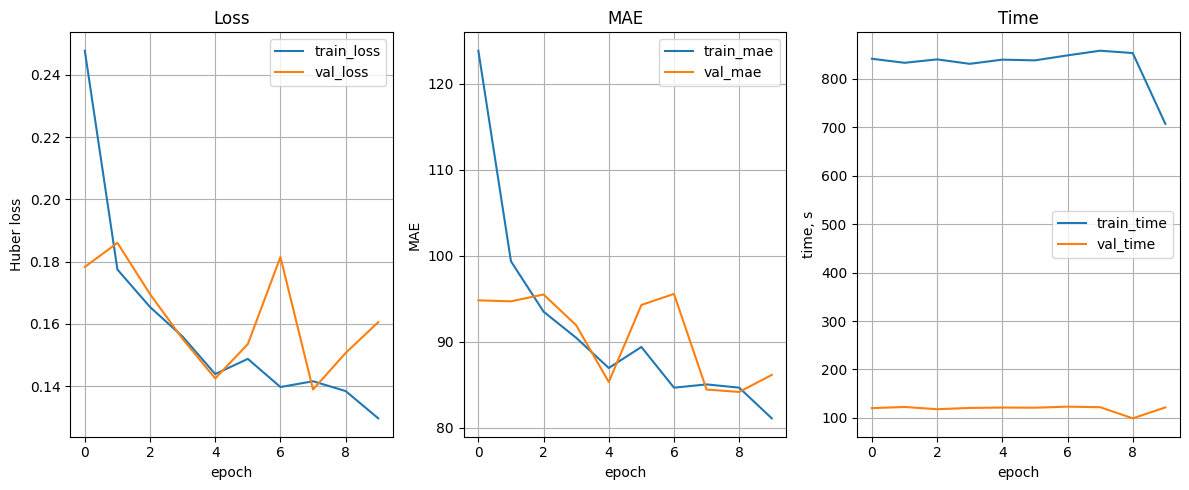

In [ ]:
import pathlib as path
import pandas as pd

log_path  = path.Path(config.MODEL_LOG_SAVE_PATH)
train_loss_history = pd.read_csv(log_path / 'experiment-1' / 'train_loss_history.csv')
train_mae_history = pd.read_csv(log_path / 'experiment-1' / 'train_mae_history.csv')
train_time_history = pd.read_csv(log_path / 'experiment-1' / 'train_time_history.csv')

val_loss_history = pd.read_csv(log_path / 'experiment-1' / 'val_loss_history.csv')
val_mae_history = pd.read_csv(log_path / 'experiment-1' / 'val_mae_history.csv')
val_time_history = pd.read_csv(log_path / 'experiment-1' / 'val_time_history.csv')

plof_train_log(train_loss_history, val_loss_history, train_mae_history, val_mae_history, train_time_history, val_time_history)

Копия результатов данного эксперимента (модель и журнал обучения) сохранены в `data/model/experiment1`

##### Чистая проверка на тесте обученной модели

In [22]:
import numpy as np
import pandas as pd
import pathlib as path
from functools import partial
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel

# local scripts
import scripts.dataset as dataset
import scripts.utils as utils

config = utils.MealModelConfig()

utils.set_random(config.SEED)

tokenizer = AutoTokenizer.from_pretrained(config.TEXT_MODEL_NAME)
val_dataset = dataset.MealDataset(model_config=config, split='test')
val_dataloader = DataLoader(dataset=val_dataset, batch_size=config.N_BATCH, shuffle=False, collate_fn=partial(dataset.collate_fn, tokenizer=tokenizer))

model_exp1 = utils.MealModelNN(config=config) 
# load trained model
model_exp1.load_state_dict(torch.load(path.Path(config.MODEL_SAVE_PATH) / 'experiment-1' / config.MODEL_SAVE_NAME))
 
loss_huber, metric_mae, time = utils.validate(model=model_exp1, config=config, dataloader=val_dataloader)
print(f'Test metric - MAE = {metric_mae}')


   -- validate()


validation: 100%|██████████| 63/63 [02:01<00:00,  1.93s/it]

Test metric - MAE = 83.65887272547162


##### Результат 
Эксперимент 1 
- модель с замороженными весами (без fine-tuning)
- слияние через конкатенацию + линейный слой - активация - dropout
- 10 эпох
- батч из 8 объектов
- время обучения на CPU (локально) - 158 мин (~ 2,5 часа) / ~ 14 мин/эпоха на train + 2 мин/эпоха на val
- лучшая модель получена на 9-ой эпохе с метриками
    - epoch - 8: train mae = 84.64, train_loss = 0.14/853.43 sec, val_mae = 84.14, val_loss = 0.15/99.13 sec
- модель сохранена в - data\model\experiment-1\best_model.pth
- чистый прогон на test - показал метрику MAE = 83.65887272547162

### Эксперимент 2 - разморозка весов
Цель:
- модель скорее всего дальше не может обучаться
- так как уже не хватает признаков от исходных моделей.

Изменения подхода:
1. разморозить последние слои:
    - DistilBERT: transformer.layer.5
    - MobileNet: blocks.4 | conv_head | norm_head
    - так чтобы дообучить текстовые признаки и признаки изображений для понимания пищевой специфики

2. меняем параметры обучения - так как добавились глубокие слои моделей - уменьшаем шаг для моделей, увеличиваем dropout, увеличиваем батч и число эпох
    - LR_TEXT_MODEL = 1e-5
    - LR_IMG_MODEL = 1e-5
    - DROPOUT_FEATURES = 0.2
    - DROPOUT_FUSION = 0.2
    - N_BATCH = 32
    - N_EPOCHS = 20
    - PATIENCE = 4

3. увеличиваем прогрев learning_rate - по формуле (1.7 x итераций на батч)

In [ ]:
import numpy as np
import pandas as pd
import pathlib as path
from functools import partial
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel

# local scripts
import scripts.dataset as dataset
import scripts.utils as utils

config = utils.MealModelConfig()

utils.set_random(config.SEED)
log = partial(utils.log_fn, config=config)

tokenizer = AutoTokenizer.from_pretrained(config.TEXT_MODEL_NAME)

train_dataset = dataset.MealDataset(model_config=config, split='train')
train_dataloader = DataLoader(dataset=train_dataset, batch_size=config.N_BATCH, shuffle=True, collate_fn=partial(dataset.collate_fn, tokenizer=tokenizer))

val_dataset = dataset.MealDataset(model_config=config, split='test')
val_dataloader = DataLoader(dataset=val_dataset, batch_size=config.N_BATCH, shuffle=False, collate_fn=partial(dataset.collate_fn, tokenizer=tokenizer))

model = utils.MealModelNN(config=config) 

# разморозка параметров
utils.unfreeze_model_params(model, config)

# подключаем обучаемые (активные) параметры к оптимизатору
optimizer = torch.optim.AdamW([
    {'params': [p for p in model.text_model.parameters() if p.requires_grad], 'lr': config.LR_TEXT_MODEL},
    {'params':[p for p in model.img_model.parameters() if p.requires_grad], 'lr': config.LR_IMG_MODEL},
    
    {'params': model.text_proj.parameters(), 'lr': config.LR_PROJ},
    {'params': model.img_proj.parameters(), 'lr': config.LR_PROJ},
    {'params': model.norm_layer.parameters(), 'lr': config.LR_PROJ},
    {'params': model.fusion.parameters(), 'lr': config.LR_FUSION},
    {'params': model.regression_head.parameters(), 'lr': config.LR_REGRESSION_HEAD}
])

# проверка, что все активные параметры добавлены в оптимизатор
utils.optimizer_params_sanity_check(model, optimizer)

# - прогрев learning rate warmup
iters_per_epoch = len(train_dataloader)
warmup_steps = int(1.7 * iters_per_epoch)   # ≈1.7 эпохи
print(f'warmup_steps = {warmup_steps}')
scheduler = torch.optim.lr_scheduler.LambdaLR(
    optimizer,
    lr_lambda=lambda step: min(1.0, step / warmup_steps)  # 150 шагов ≈ 1.7 эпохи при BATCH=32
)

print(f'batch size = {config.N_BATCH}')
print(f'n_iter = {config.N_ITER}')
print(f'train iterations/batch = {len(train_dataloader)}')
print(f'val iterations/batch = {len(val_dataloader)}')

train_loss_history = []
train_mae_history = []
train_time_history = []
val_loss_history = []
val_mae_history = []
val_time_history = []
best_metric = 1000
best_epoch = -1
for epoch in range(config.N_EPOCHS):
    train_huber_loss, train_metric_mae, train_time = utils.train(model=model, config=config, optimizer=optimizer, dataloader=train_dataloader, scheduler=scheduler)
    train_loss_history.append(train_huber_loss)
    train_mae_history.append(train_metric_mae)
    train_time_history.append(train_time)

    val_loss_huber, val_metric_mae, val_time = utils.validate(model=model, config=config, dataloader=val_dataloader)
    val_loss_history.append(val_loss_huber)
    val_mae_history.append(val_metric_mae)
    val_time_history.append(val_time)

    print(f'epoch - {epoch}: train mae = {train_metric_mae:.2f}, train_loss = {train_huber_loss:.2f}/{train_time:.2f} sec, val_mae = {val_metric_mae:.2f}, val_loss = {val_loss_huber:.2f}/{val_time:.2f} sec')
       
    if val_metric_mae < best_metric:
        best_metric = val_metric_mae
        best_epoch = epoch
        utils.save_model(model, config)

    # если метрика не уменьшается в течение config.PATIENCE эпох подряд, то останавливаем обучение
    if (epoch - best_epoch) >= config.PATIENCE:
        print(f'early stopping - metric is not increasing for [{config.PATIENCE}] epochs')
        break


    if val_metric_mae < config.TARGET_METRIC:
        print(f'!! target metric reached = {config.TARGET_METRIC}, stop training')
        break

# save train logs
log_path  = path.Path(config.MODEL_LOG_SAVE_PATH)
log_path.mkdir(exist_ok=True)

pd.DataFrame(train_loss_history, columns=['loss_huber']).to_csv(log_path / 'train_loss_history.csv', index=False)
pd.DataFrame(train_mae_history, columns=['metric_mae']).to_csv(log_path / 'train_mae_history.csv', index=False)
pd.DataFrame(train_time_history, columns=['time']).to_csv(log_path / 'train_time_history.csv', index=False)

pd.DataFrame(val_loss_history, columns=['loss_huber']).to_csv(log_path / 'val_loss_history.csv', index=False)
pd.DataFrame(val_mae_history, columns=['metric_mae']).to_csv(log_path / 'val_mae_history.csv', index=False)
pd.DataFrame(val_time_history, columns=['time']).to_csv(log_path / 'val_time_history.csv', index=False)

#### Выполнение на ВМ с GPU
Выполняется в другом ноутбуке на GPU
- история скопирована в data/model/experiment-2

```
expected TARGET_MEAN = 255, real data =  255.31
expected TARGET_STD  = 221, real data = 220.71
distilbert-base-uncased - parameter id unfreezed: transformer.layer.5.attention.q_lin.weight
distilbert-base-uncased - parameter id unfreezed: transformer.layer.5.attention.q_lin.bias
distilbert-base-uncased - parameter id unfreezed: transformer.layer.5.attention.k_lin.weight
distilbert-base-uncased - parameter id unfreezed: transformer.layer.5.attention.k_lin.bias
distilbert-base-uncased - parameter id unfreezed: transformer.layer.5.attention.v_lin.weight
distilbert-base-uncased - parameter id unfreezed: transformer.layer.5.attention.v_lin.bias
distilbert-base-uncased - parameter id unfreezed: transformer.layer.5.attention.out_lin.weight
distilbert-base-uncased - parameter id unfreezed: transformer.layer.5.attention.out_lin.bias
distilbert-base-uncased - parameter id unfreezed: transformer.layer.5.sa_layer_norm.weight
distilbert-base-uncased - parameter id unfreezed: transformer.layer.5.sa_layer_norm.bias
distilbert-base-uncased - parameter id unfreezed: transformer.layer.5.ffn.lin1.weight
distilbert-base-uncased - parameter id unfreezed: transformer.layer.5.ffn.lin1.bias
distilbert-base-uncased - parameter id unfreezed: transformer.layer.5.ffn.lin2.weight
distilbert-base-uncased - parameter id unfreezed: transformer.layer.5.ffn.lin2.bias
distilbert-base-uncased - parameter id unfreezed: transformer.layer.5.output_layer_norm.weight
distilbert-base-uncased - parameter id unfreezed: transformer.layer.5.output_layer_norm.bias
mobilenetv4_conv_aa_large - parameter id unfreezed: blocks.4.0.conv.weight
mobilenetv4_conv_aa_large - parameter id unfreezed: blocks.4.0.bn1.weight
mobilenetv4_conv_aa_large - parameter id unfreezed: blocks.4.0.bn1.bias
mobilenetv4_conv_aa_large - parameter id unfreezed: conv_head.weight
mobilenetv4_conv_aa_large - parameter id unfreezed: norm_head.weight
mobilenetv4_conv_aa_large - parameter id unfreezed: norm_head.bias
batch size = 32
n_iter = -1
train iterations/batch = 86
val iterations/batch = 16
   --- train()
training: 100%|██████████| 86/86 [01:05<00:00,  1.31it/s]
validation: 100%|██████████| 16/16 [00:11<00:00,  1.43it/s]
epoch - 0: train mae = 142.99, train_loss = 0.31/65.60 sec, val_mae = 107.78, val_loss = 0.21/11.20 sec
model saved to - [data/model/best_model.pth]
   --- train()
training: 100%|██████████| 86/86 [01:08<00:00,  1.26it/s]
validation: 100%|██████████| 16/16 [00:11<00:00,  1.39it/s]
epoch - 1: train mae = 106.41, train_loss = 0.19/68.19 sec, val_mae = 101.24, val_loss = 0.16/11.53 sec
model saved to - [data/model/best_model.pth]
   --- train()
training: 100%|██████████| 86/86 [01:05<00:00,  1.30it/s]
validation: 100%|██████████| 16/16 [00:11<00:00,  1.43it/s]
epoch - 2: train mae = 92.77, train_loss = 0.16/65.99 sec, val_mae = 82.92, val_loss = 0.14/11.21 sec
model saved to - [data/model/best_model.pth]
   --- train()
training: 100%|██████████| 86/86 [01:05<00:00,  1.31it/s]
validation: 100%|██████████| 16/16 [00:11<00:00,  1.44it/s]
epoch - 3: train mae = 86.09, train_loss = 0.14/65.89 sec, val_mae = 81.08, val_loss = 0.13/11.12 sec
model saved to - [data/model/best_model.pth]
   --- train()
training: 100%|██████████| 86/86 [01:05<00:00,  1.30it/s]
validation: 100%|██████████| 16/16 [00:11<00:00,  1.43it/s]
epoch - 4: train mae = 77.38, train_loss = 0.12/65.99 sec, val_mae = 86.92, val_loss = 0.13/11.21 sec
   --- train()
training: 100%|██████████| 86/86 [01:05<00:00,  1.31it/s]
validation: 100%|██████████| 16/16 [00:11<00:00,  1.44it/s]
epoch - 5: train mae = 76.51, train_loss = 0.12/65.89 sec, val_mae = 76.95, val_loss = 0.13/11.15 sec
model saved to - [data/model/best_model.pth]
   --- train()
training: 100%|██████████| 86/86 [01:05<00:00,  1.30it/s]
validation: 100%|██████████| 16/16 [00:11<00:00,  1.43it/s]
epoch - 6: train mae = 75.24, train_loss = 0.11/65.99 sec, val_mae = 75.85, val_loss = 0.12/11.15 sec
model saved to - [data/model/best_model.pth]
   --- train()
training: 100%|██████████| 86/86 [01:05<00:00,  1.30it/s]
validation: 100%|██████████| 16/16 [00:11<00:00,  1.43it/s]
epoch - 7: train mae = 72.77, train_loss = 0.10/65.94 sec, val_mae = 72.48, val_loss = 0.11/11.23 sec
model saved to - [data/model/best_model.pth]
   --- train()
training: 100%|██████████| 86/86 [01:05<00:00,  1.30it/s]
validation: 100%|██████████| 16/16 [00:11<00:00,  1.42it/s]
epoch - 8: train mae = 68.22, train_loss = 0.09/65.99 sec, val_mae = 81.93, val_loss = 0.12/11.24 sec
   --- train()
training: 100%|██████████| 86/86 [01:06<00:00,  1.30it/s]
validation: 100%|██████████| 16/16 [00:11<00:00,  1.43it/s]
epoch - 9: train mae = 68.09, train_loss = 0.09/66.03 sec, val_mae = 76.21, val_loss = 0.12/11.22 sec
   --- train()
training: 100%|██████████| 86/86 [01:05<00:00,  1.30it/s]
validation: 100%|██████████| 16/16 [00:11<00:00,  1.42it/s]
epoch - 10: train mae = 66.38, train_loss = 0.09/65.91 sec, val_mae = 75.01, val_loss = 0.11/11.25 sec
   --- train()
training: 100%|██████████| 86/86 [01:05<00:00,  1.30it/s]
validation: 100%|██████████| 16/16 [00:11<00:00,  1.42it/s]
epoch - 11: train mae = 66.15, train_loss = 0.09/66.00 sec, val_mae = 71.72, val_loss = 0.11/11.27 sec
model saved to - [data/model/best_model.pth]
   --- train()
training: 100%|██████████| 86/86 [01:05<00:00,  1.30it/s]
validation: 100%|██████████| 16/16 [00:11<00:00,  1.42it/s]
epoch - 12: train mae = 62.56, train_loss = 0.08/65.98 sec, val_mae = 74.80, val_loss = 0.11/11.27 sec
   --- train()
training: 100%|██████████| 86/86 [01:05<00:00,  1.30it/s]
validation: 100%|██████████| 16/16 [00:11<00:00,  1.42it/s]
epoch - 13: train mae = 60.70, train_loss = 0.08/65.99 sec, val_mae = 74.73, val_loss = 0.12/11.25 sec
   --- train()
training: 100%|██████████| 86/86 [01:06<00:00,  1.30it/s]
validation: 100%|██████████| 16/16 [00:11<00:00,  1.43it/s]
epoch - 14: train mae = 59.63, train_loss = 0.07/66.09 sec, val_mae = 73.23, val_loss = 0.11/11.21 sec
   --- train()
training: 100%|██████████| 86/86 [01:06<00:00,  1.30it/s]
validation: 100%|██████████| 16/16 [00:11<00:00,  1.43it/s]
epoch - 15: train mae = 58.53, train_loss = 0.07/66.15 sec, val_mae = 71.79, val_loss = 0.11/11.17 sec
early stopping - metric is not increasing for [4] epochs 

```

#### Результат
- лучший результат эпоха - 11 (из 15 с ранней остановкой) - val_mae = 71.72

#### Печать журнала обучения

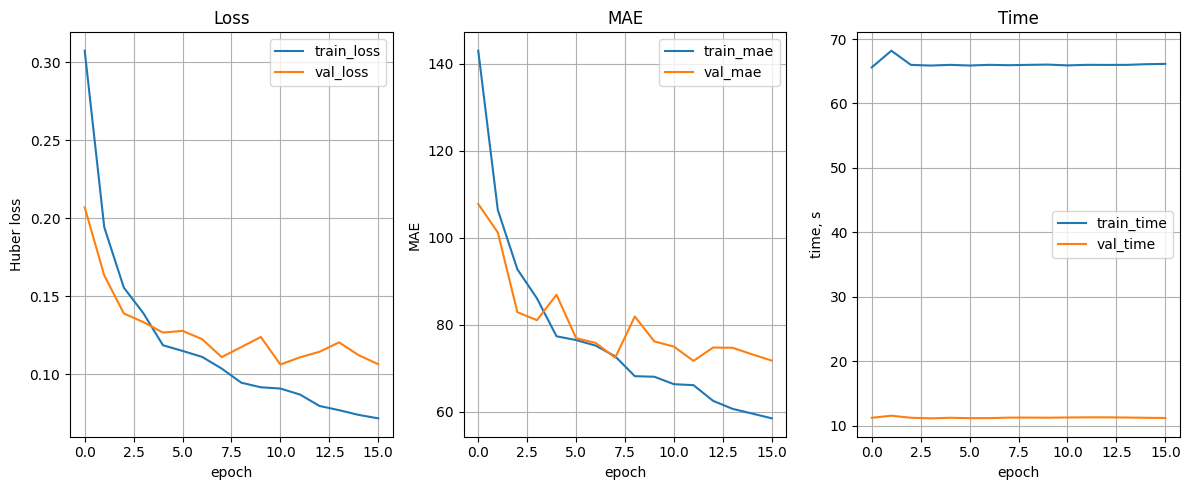

In [65]:
import pathlib as path
import pandas as pd

log_path  = path.Path(config.MODEL_LOG_SAVE_PATH)
exp_name = 'experiment-2'
log_path = log_path / exp_name

train_loss_history = pd.read_csv(log_path / 'train_loss_history.csv')
train_mae_history = pd.read_csv(log_path / 'train_mae_history.csv')
train_time_history = pd.read_csv(log_path / 'train_time_history.csv') 

val_loss_history = pd.read_csv(log_path / 'val_loss_history.csv')
val_mae_history = pd.read_csv(log_path /  'val_mae_history.csv')
val_time_history = pd.read_csv(log_path / 'val_time_history.csv')

plof_train_log(train_loss_history, val_loss_history, train_mae_history, val_mae_history, train_time_history, val_time_history)